In [ ]:
import pandas as pd
import numpy as np

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

# =====================================
# 1. LOAD EXPERIMENTAL DATA
# =====================================

file = "data.xlsx"

df = pd.read_excel(file)

df.columns = [
    "I", "V", "Wm_i", "Wt_i",
    "Wm_f", "Wt_f", "t", "mrr", "twr"
]

df = df.dropna(
    subset=["I", "V", "Wm_i", "Wm_f",
            "Wt_i", "Wt_f", "t"]
).copy()

df = df[df["t"] > 0].copy()

# Calculate MRR and TWR
df["mrr"] = (df["Wm_i"] - df["Wm_f"]) / df["t"]
df["twr"] = (df["Wt_i"] - df["Wt_f"]) / df["t"]

X = df[["I", "V"]]

# =====================================
# 2. TRAIN-TEST SPLIT (80:20)
# =====================================

indices = np.arange(len(df))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

# =====================================
# 3. MODEL TRAINING AND EVALUATION
# =====================================

models = {}

for name in ["mrr", "twr"]:

    y = df[name]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    # Train evaluation model
    model = LinearRegression()
    model.fit(X_train, y_train)

    # Predictions
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    # Store training model for evaluation
    models[name] = model

    # ---------------------------------
    # Calculate performance metrics
    # ---------------------------------

    def calculate_metrics(actual, predicted):

        r2 = r2_score(actual, predicted)

        n = len(actual)
        p = 2

        adj_r2 = (
            1 - (1 - r2) * (n - 1) / (n - p - 1)
            if n > p + 1 else np.nan
        )

        mse = mean_squared_error(actual, predicted)
        rmse = np.sqrt(mse)
        mae = mean_absolute_error(actual, predicted)

        actual = np.asarray(actual)
        nonzero = np.abs(actual) > 1e-12

        mape = (
            np.mean(
                np.abs(
                    (actual[nonzero] - predicted[nonzero])
                    / actual[nonzero]
                )
            ) * 100
            if nonzero.any() else np.nan
        )

        return r2, adj_r2, mse, rmse, mae, mape

    train_metrics = calculate_metrics(y_train, train_pred)
    test_metrics = calculate_metrics(y_test, test_pred)

    # ---------------------------------
    # Display results
    # ---------------------------------

    print("\n" + "=" * 55)
    print(f"       {name.upper()} REGRESSION PERFORMANCE")
    print("=" * 55)

    print("\nTRAINING PERFORMANCE (80%)")

    print(f"R2          : {train_metrics[0]:.6f}")
    print(f"Adjusted R2 : {train_metrics[1]:.6f}")
    print(f"MSE         : {train_metrics[2]:.6e}")
    print(f"RMSE        : {train_metrics[3]:.6e}")
    print(f"MAE         : {train_metrics[4]:.6e}")
    print(f"MAPE        : {train_metrics[5]:.4f}%")

    print("\nTESTING PERFORMANCE (20%)")

    print(f"R2          : {test_metrics[0]:.6f}")
    print(f"Adjusted R2 : {test_metrics[1]:.6f}")
    print(f"MSE         : {test_metrics[2]:.6e}")
    print(f"RMSE        : {test_metrics[3]:.6e}")
    print(f"MAE         : {test_metrics[4]:.6e}")
    print(f"MAPE        : {test_metrics[5]:.4f}%")

# =====================================
# 4. TRAIN FINAL MODELS ON FULL DATA
# =====================================

final_models = {}

for name in ["mrr", "twr"]:

    final_model = LinearRegression()
    final_model.fit(X, df[name])

    final_models[name] = final_model

# =====================================
# 5. CUSTOM INPUT PREDICTION
# =====================================

print("\n" + "=" * 55)
print("             CUSTOM EDM PREDICTION")
print("=" * 55)

while True:

    try:
        current = float(input("\nEnter Current (A): "))
        voltage = float(input("Enter Voltage (V): "))

        if current < 0 or voltage < 0:
            print("Enter non-negative values.")
            continue

        break

    except ValueError:
        print("Invalid input. Enter numerical values.")

# Check experimental range
if not (
    df["I"].min() <= current <= df["I"].max()
    and df["V"].min() <= voltage <= df["V"].max()
):
    print("\nWARNING: Input is outside the experimental range.")
    print("Prediction may be unreliable.")

custom_input = pd.DataFrame({
    "I": [current],
    "V": [voltage]
})

# Predict using final models trained on 100% data
mrr = final_models["mrr"].predict(custom_input)[0]
twr = final_models["twr"].predict(custom_input)[0]

print("\n------------- PREDICTION RESULTS -------------")

print(f"Current : {current} A")
print(f"Voltage : {voltage} V")

print(f"\nPredicted MRR : {mrr:.6e} g/s")
print(f"Predicted TWR : {twr:.6e} g/s")

print("=" * 55)



       MRR REGRESSION PERFORMANCE

TRAINING PERFORMANCE (80%)
R2          : 0.924533
Adjusted R2 : 0.912923
MSE         : 2.994589e-07
RMSE        : 5.472284e-04
MAE         : 4.560218e-04
MAPE        : 11.2452%

TESTING PERFORMANCE (20%)
R2          : 0.707373
Adjusted R2 : 0.414745
MSE         : 1.060916e-06
RMSE        : 1.030008e-03
MAE         : 7.969151e-04
MAPE        : 21.6115%

       TWR REGRESSION PERFORMANCE

TRAINING PERFORMANCE (80%)
R2          : 0.887801
Adjusted R2 : 0.870539
MSE         : 2.012272e-09
RMSE        : 4.485835e-05
MAE         : 3.857366e-05
MAPE        : 119.5882%

TESTING PERFORMANCE (20%)
R2          : 0.407278
Adjusted R2 : -0.185443
MSE         : 7.657696e-09
RMSE        : 8.750827e-05
MAE         : 8.037759e-05
MAPE        : 604.5129%

             CUSTOM EDM PREDICTION

Enter Current (A): 27.5
Enter Voltage (V): 75

------------- PREDICTION RESULTS -------------
Current : 27.5 A
Voltage : 75.0 V

Predicted MRR : 6.100526e-03 g/s
Predicted TWR : 2.

In [ ]:

import pandas as pd
import numpy as np

df = pd.read_excel("data.xlsx")

df.columns = [
    "I", "V", "Wm_i", "Wt_i",
    "Wm_f", "Wt_f", "t", "mrr", "twr"
]

# Convert measurements to numeric
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove invalid observations
df = df.dropna(
    subset=["I", "V", "Wm_i", "Wm_f",
            "Wt_i", "Wt_f", "t"]
)

df = df[df["t"] > 0].copy()

# Calculate MRR and TWR
df["mrr"] = (df["Wm_i"] - df["Wm_f"]) / df["t"]
df["twr"] = (df["Wt_i"] - df["Wt_f"]) / df["t"]

# Normalize MRR (higher is better)
df["MRR_score"] = (
    (df["mrr"] - df["mrr"].min()) /
    (df["mrr"].max() - df["mrr"].min())
)

# Normalize TWR (lower is better)
df["TWR_score"] = (
    (df["twr"].max() - df["twr"]) /
    (df["twr"].max() - df["twr"].min())
)

# Equal-weight multi-objective score
df["Optimization_score"] = (
    0.5 * df["MRR_score"] +
    0.5 * df["TWR_score"]
)

# Best compromise
best = df.loc[df["Optimization_score"].idxmax()]

print("\n===== EDM OPTIMIZATION RESULTS =====")

print("\nMaximum MRR:")
print(df.loc[df["mrr"].idxmax(),
             ["I", "V", "mrr", "twr"]])

print("\nMinimum TWR:")
print(df.loc[df["twr"].idxmin(),
             ["I", "V", "mrr", "twr"]])

print("\nBest Multi-objective Combination:")
print(best[["I", "V", "mrr", "twr",
            "Optimization_score"]])

print("\nTop 5 combinations:")
print(
    df.sort_values(
        "Optimization_score",
        ascending=False
    )[["I", "V", "mrr", "twr",
       "Optimization_score"]].head(5)
)



===== EDM OPTIMIZATION RESULTS =====

Maximum MRR:
I      30.000000
V      60.000000
mrr     0.008031
twr     0.000289
Name: 22, dtype: float64

Minimum TWR:
I      10.000000
V      90.000000
mrr     0.001000
twr     0.000004
Name: 4, dtype: float64

Best Multi-objective Combination:
I                     25.000000
V                     30.000000
mrr                    0.007308
twr                    0.000114
Optimization_score     0.810095
Name: 15, dtype: float64

Top 5 combinations:
     I   V       mrr       twr  Optimization_score
15  25  30  0.007308  0.000114            0.810095
5   15  30  0.006003  0.000049            0.798793
11  20  45  0.006053  0.000068            0.778401
7   15  60  0.004909  0.000013            0.765873
6   15  45  0.004838  0.000018            0.754711


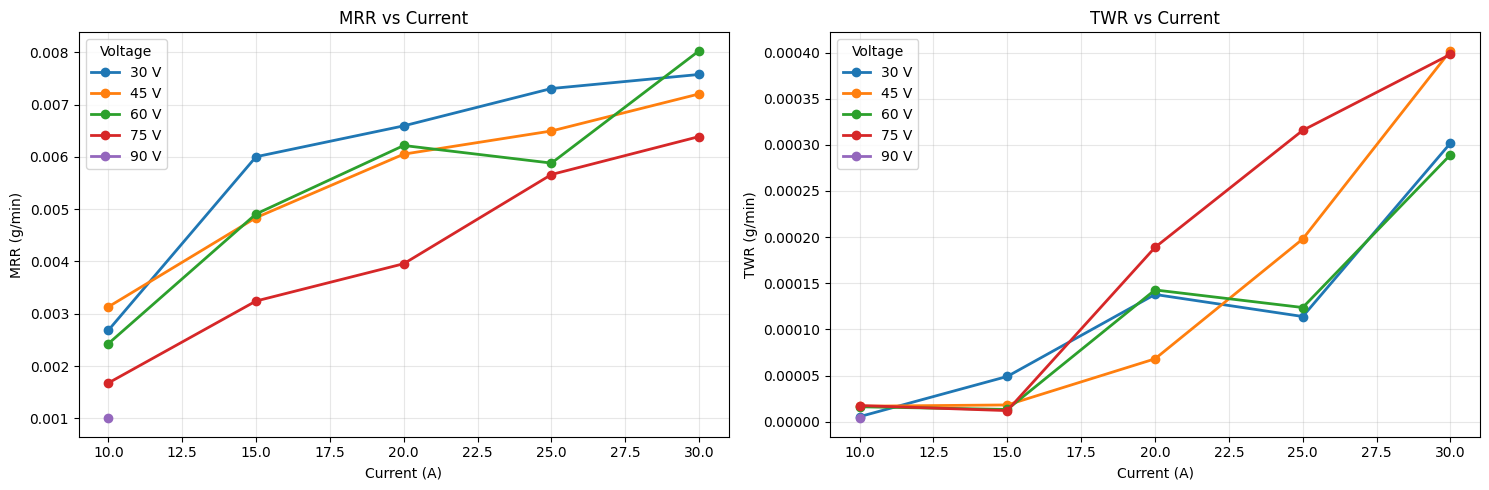

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Read Excel file
df = pd.read_excel('data.xlsx')

# Map columns sequentially to avoid spelling and case mismatch errors
# Excel columns: 0: Current, 1: Voltage, 2: Wm_i, 3: Wt_i, 4: Wm_f, 5: Wt_f, 6: Time
df.columns = [
    'Current', 'Voltage', 'Wm_i', 'Wt_i',
    'Wm_f', 'Wt_f', 'Time'
] + list(df.columns[7:])

# Calculate MRR and TWR using the safe, mapped column names
df['MRR'] = (df['Wm_i'] - df['Wm_f']) / df['Time']
df['TWR'] = (df['Wt_i'] - df['Wt_f']) / df['Time']

voltages = sorted(df['Voltage'].dropna().unique())

# Create two graphs
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Graph 1: MRR vs Current
for v in voltages:
    data = df[df['Voltage'] == v].sort_values('Current')

    axes[0].plot(
        data['Current'], data['MRR'],
        marker='o', linewidth=2, label=f'{v} V'
    )

axes[0].set_xlabel('Current (A)')
axes[0].set_ylabel('MRR (g/min)')
axes[0].set_title('MRR vs Current')
axes[0].legend(title='Voltage')
axes[0].grid(True, alpha=0.3)

# Graph 2: TWR vs Current
for v in voltages:
    data = df[df['Voltage'] == v].sort_values('Current')

    axes[1].plot(
        data['Current'], data['TWR'],
        marker='o', linewidth=2, label=f'{v} V'
    )

axes[1].set_xlabel('Current (A)')
axes[1].set_ylabel('TWR (g/min)')
axes[1].set_title('TWR vs Current')
axes[1].legend(title='Voltage')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Effect of Current and Voltage on MRR and TWR

The experimental results indicate that discharge current has a significant influence on both Material Removal Rate (MRR) and Tool Wear Rate (TWR). With an increase in current, both MRR and TWR generally increase due to higher discharge energy and increased thermal erosion of the workpiece and tool electrodes.

However, MRR shows a generally decreasing trend with an increase in voltage at a constant current. This behaviour may be attributed to changes in the inter-electrode gap, ignition delay and discharge frequency, which influence the effective energy supplied for material removal.

Unlike MRR, TWR does not show a consistent trend with voltage. This may be due to changes in the distribution of discharge energy between the tool and workpiece electrodes and the influence of other machining conditions.

Overall, current appears to be an important parameter controlling material removal and tool wear, while the effect of voltage is more dependent on the discharge conditions.